# Exploring the Mauna Loa CO₂ Record with pandas

This notebook loads NOAA's monthly mean atmospheric CO₂ measurements from Mauna Loa Observatory (the "Keeling Curve"), inspects the data as text, and makes a few plots.

**Data file:** `data/co2_mm_mlo.csv`, downloaded from NOAA GML:
https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv

Columns:
- `year`, `month`, `decimal date`: when the measurement was taken
- `average`: monthly mean CO₂ in ppm (parts per million)
- `deseasonalized`: the monthly mean with the average seasonal cycle removed
- `ndays`, `sdev`, `unc`: number of measurement days, standard deviation, and uncertainty. Negative values mean "not available".

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_FILE = "data/co2_mm_mlo.csv"

## 1. Load the data

The file starts with a block of header text where every line begins with `#`. Passing `comment="#"` tells pandas to skip those lines.

In [2]:
df = pd.read_csv(DATA_FILE, comment="#")

# Tidy the column names: "decimal date" -> "decimal_date"
df.columns = df.columns.str.strip().str.replace(" ", "_")

df.head()

,year,month,decimal_date,average,deseasonalized,ndays,sdev,unc
0,1958,3,1958.2027,315.71,314.44,-1,-9.99,-0.99
1,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99
2,1958,5,1958.3699,317.51,314.69,-1,-9.99,-0.99
3,1958,6,1958.4548,317.27,315.15,-1,-9.99,-0.99
4,1958,7,1958.5370,315.87,315.20,-1,-9.99,-0.99


Combine `year` and `month` into a real datetime and use it as the index. This makes time-based selection and plotting easy.

In [3]:
df["date"] = pd.to_datetime(dict(year=df["year"], month=df["month"], day=15))
df = df.set_index("date")
df.head()

,year,month,decimal_date,average,deseasonalized,ndays,sdev,unc
date,,,,,,,,
1958-03-15,1958,3,1958.2027,315.71,314.44,-1,-9.99,-0.99
1958-04-15,1958,4,1958.2877,317.45,315.16,-1,-9.99,-0.99
1958-05-15,1958,5,1958.3699,317.51,314.69,-1,-9.99,-0.99
1958-06-15,1958,6,1958.4548,317.27,315.15,-1,-9.99,-0.99
1958-07-15,1958,7,1958.5370,315.87,315.20,-1,-9.99,-0.99


## 2. Examine the contents as text

In [4]:
print("Shape (rows, columns):", df.shape)
print("First month:", df.index.min().strftime("%Y-%m"))
print("Last month: ", df.index.max().strftime("%Y-%m"))

Shape (rows, columns): (822, 8)
First month: 1958-03
Last month:  2026-08


In [5]:
# Column names, data types, and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 822 entries, 1958-03-15 to 2026-08-15
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   year            822 non-null    int64  
 1   month           822 non-null    int64  
 2   decimal_date    822 non-null    float64
 3   average         822 non-null    float64
 4   deseasonalized  822 non-null    float64
 5   ndays           822 non-null    int64  
 6   sdev            822 non-null    float64
 7   unc             822 non-null    float64
dtypes: float64(5), int64(3)
memory usage: 57.8 KB


In [6]:
# Summary statistics for every numeric column
df.describe()

,year,month,decimal_date,average,deseasonalized,ndays,sdev,unc
count,822.000000,822.000000,822.000000,822.000000,822.000000,822.000000,822.000000,822.000000
mean,1991.917275,6.492701,1992.416069,361.360474,361.349088,19.166667,-1.994659,-0.084988
std,19.788725,3.445673,19.787067,33.456190,33.387729,11.817644,4.479984,0.508311
min,1958.000000,1.000000,1958.202700,312.420000,314.440000,-1.000000,-9.990000,-0.990000
25%,1975.000000,4.000000,1975.312525,331.282500,330.882500,14.250000,0.210000,0.080000
50%,1992.000000,6.000000,1992.416650,356.360000,356.490000,25.000000,0.400000,0.150000
75%,2009.000000,9.000000,2009.520850,387.682500,387.712500,28.000000,0.570000,0.220000
max,2026.000000,12.000000,2026.625000,432.340000,429.510000,31.000000,1.310000,0.580000


Notice the minimums in `describe()`: `ndays = -1`, `sdev = -9.99`, `unc = -0.99`. These are **placeholder codes** for missing values, not real measurements. Convert them to `NaN` so they don't corrupt statistics or plots.

In [7]:
for col in ["ndays", "sdev", "unc"]:
    df.loc[df[col] < 0, col] = np.nan

# Count missing values in each column
df.isna().sum()

year                0
month               0
decimal_date        0
average             0
deseasonalized      0
ndays             195
sdev              196
unc               194
dtype: int64

In [8]:
# The last few rows: the most recent measurements
df.tail()

,year,month,decimal_date,average,deseasonalized,ndays,sdev,unc
date,,,,,,,,
2026-04-15,2026,4,2026.2917,431.12,428.61,23.0,1.16,0.46
2026-05-15,2026,5,2026.3750,432.34,429.06,19.0,0.64,0.28
2026-06-15,2026,6,2026.4583,431.43,428.99,19.0,0.27,0.12
2026-07-15,2026,7,2026.5417,429.13,428.78,21.0,0.61,0.26
2026-08-15,2026,8,2026.6250,427.55,429.51,17.0,0.36,0.17


In [9]:
# Select a single year using the datetime index
df.loc["2000", ["average", "deseasonalized"]]

,average,deseasonalized
date,,
2000-01-15,369.45,369.24
2000-02-15,369.71,368.99
2000-03-15,370.75,369.24
2000-04-15,371.98,369.44
2000-05-15,371.75,368.87
2000-06-15,371.87,369.66
2000-07-15,370.02,369.36
2000-08-15,368.27,369.87
2000-09-15,367.15,370.46


In [10]:
# Annual means, and how much CO2 rose each year
annual = df["average"].groupby(df.index.year).mean()
growth = annual.diff()

print("Annual mean CO2 (ppm), first and last 5 years:")
print(annual.head().round(2).to_string())
print("...")
print(annual.tail().round(2).to_string())

first, last = annual.index[0], annual.index[-1]
print(f"\nChange from {first} to {last}: {annual.iloc[-1] - annual.iloc[0]:.1f} ppm")

Annual mean CO2 (ppm), first and last 5 years:
date
1958    315.24
1959    315.98
1960    316.91
1961    317.64
1962    318.45
...
date
2022    418.53
2023    421.08
2024    424.60
2025    427.35
2026    429.96

Change from 1958 to 2026: 114.7 ppm


Note: the first and last years may be partial (the record starts in March 1958, and the current year is incomplete), so their annual means are slightly biased by the seasonal cycle.

## 3. Visualize the data

### 3a. The Keeling Curve

Monthly means show the long-term rise plus a seasonal wiggle. The deseasonalized series shows just the trend.

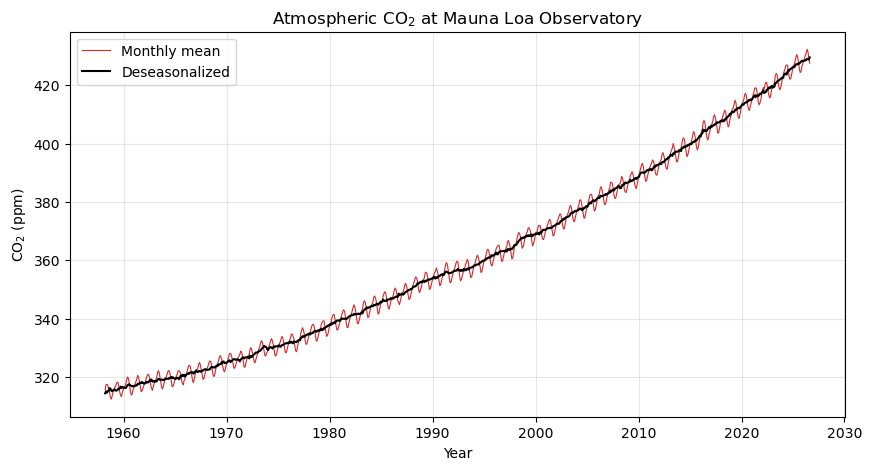

In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(df.index, df["average"], lw=0.8, color="tab:red", label="Monthly mean")
ax.plot(df.index, df["deseasonalized"], lw=1.5, color="black", label="Deseasonalized")
ax.set_xlabel("Year")
ax.set_ylabel("CO$_2$ (ppm)")
ax.set_title("Atmospheric CO$_2$ at Mauna Loa Observatory")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### 3b. Zoom in on recent years

Over a few years, the seasonal cycle is easy to see: CO₂ peaks in late spring and bottoms out in early autumn, following Northern Hemisphere plant growth.

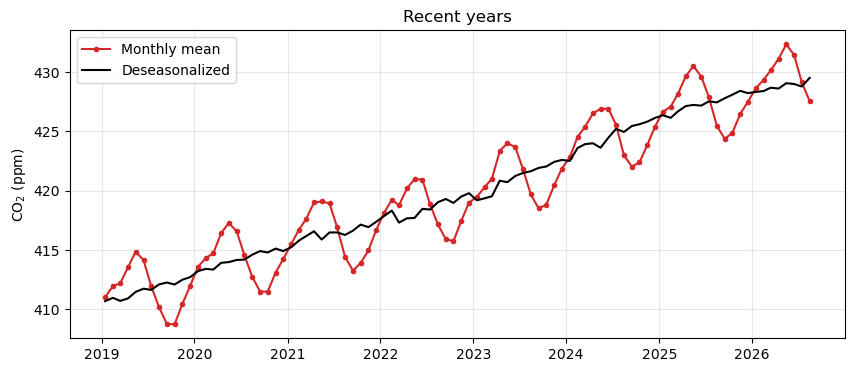

In [12]:
recent = df.loc["2019":]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(recent.index, recent["average"], marker="o", ms=3, color="tab:red", label="Monthly mean")
ax.plot(recent.index, recent["deseasonalized"], color="black", label="Deseasonalized")
ax.set_ylabel("CO$_2$ (ppm)")
ax.set_title("Recent years")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### 3c. The average seasonal cycle

Subtract the deseasonalized trend from each monthly value to isolate the seasonal part, then average by calendar month.

       mean   std
month            
1      0.12  0.15
2      0.75  0.13
3      1.49  0.13
4      2.57  0.15
5      3.09  0.18
6      2.32  0.10
7      0.61  0.16
8     -1.58  0.23
9     -3.24  0.20
10    -3.25  0.12
11    -2.05  0.10
12    -0.81  0.09


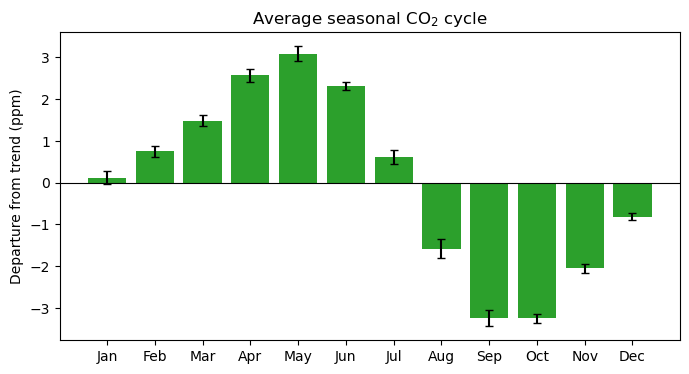

In [13]:
df["seasonal"] = df["average"] - df["deseasonalized"]
cycle = df.groupby("month")["seasonal"].agg(["mean", "std"])
print(cycle.round(2))

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(cycle.index, cycle["mean"], yerr=cycle["std"], capsize=3, color="tab:green")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(cycle.index)
ax.set_xticklabels(month_names)
ax.set_ylabel("Departure from trend (ppm)")
ax.set_title("Average seasonal CO$_2$ cycle")
plt.show()

### 3d. Is the rise speeding up?

Plot the year-over-year increase in the annual mean. Partial first and last years are dropped.

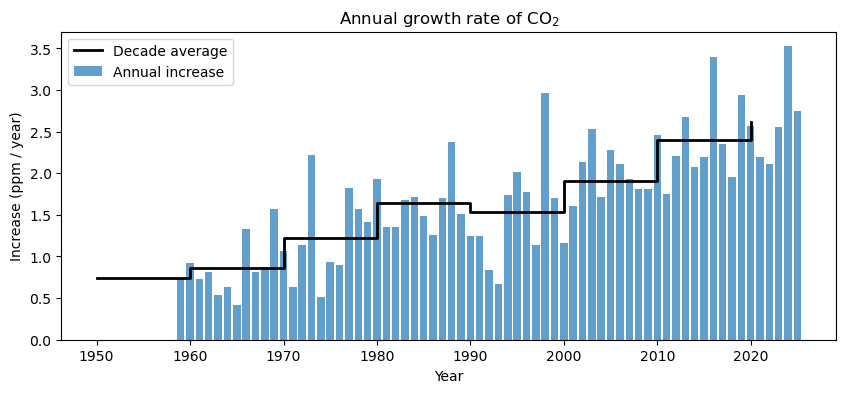

Average growth rate by decade (ppm/yr):
date
1950    0.74
1960    0.86
1970    1.22
1980    1.64
1990    1.53
2000    1.91
2010    2.40
2020    2.62


In [14]:
growth_full = growth.iloc[1:-1]   # drop the undefined first diff and the partial final year
decade_avg = growth_full.groupby((growth_full.index // 10) * 10).mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(growth_full.index, growth_full.values, color="tab:blue", alpha=0.7, label="Annual increase")
ax.step(decade_avg.index, decade_avg.values, where="post", color="black", lw=2, label="Decade average")
ax.set_xlabel("Year")
ax.set_ylabel("Increase (ppm / year)")
ax.set_title("Annual growth rate of CO$_2$")
ax.legend()
plt.show()

print("Average growth rate by decade (ppm/yr):")
print(decade_avg.round(2).to_string())

### 3e. Distribution of the monthly values

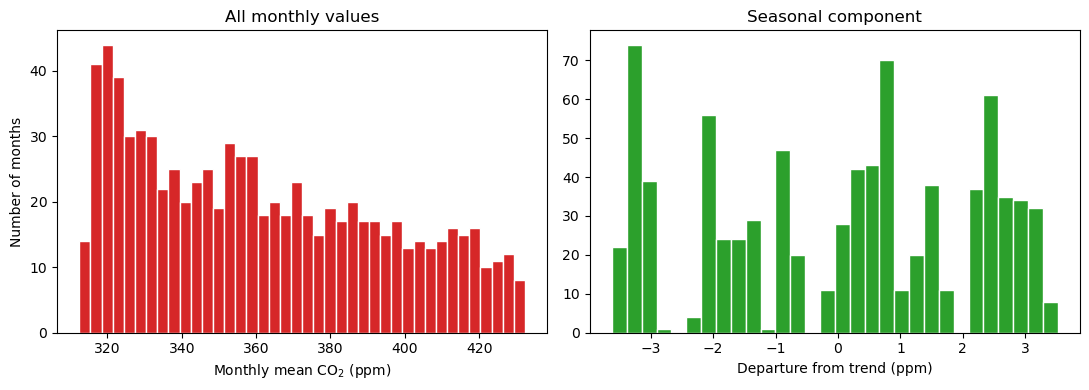

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["average"], bins=40, color="tab:red", edgecolor="white")
axes[0].set_xlabel("Monthly mean CO$_2$ (ppm)")
axes[0].set_ylabel("Number of months")
axes[0].set_title("All monthly values")

axes[1].hist(df["seasonal"], bins=30, color="tab:green", edgecolor="white")
axes[1].set_xlabel("Departure from trend (ppm)")
axes[1].set_title("Seasonal component")

plt.tight_layout()
plt.show()

## Things to try

- Fit a quadratic to `deseasonalized` vs. `decimal_date` with `np.polyfit` and extrapolate to 2050.
- Does the size of the seasonal cycle (max minus min each year) change over time?
- Plot `unc` over time: when did the measurement uncertainty become available, and how has it changed?